In [1]:
#Program 1
import pandas as pd
import numpy as np
data=pd.read_csv(r"D:\Sem3\iris.csv")
data
mn=np.mean(data['sepal_length'])
med=np.median(data['sepal_length'])
mod=data['sepal_length'].mode()
st=np.std(data['sepal_length'])
var=np.var(data['sepal_length'])
print(mn)
print(med)
print(mod)
print(st)
print(var)

5.843333333333334
5.8
0    5.0
Name: sepal_length, dtype: float64
0.8253012917851409
0.6811222222222223


Intercept: 4.297371533031884
Coefficient: 0.40557884202140376
 MSE:0.13
 RMSE:0.36
 R2:0.81


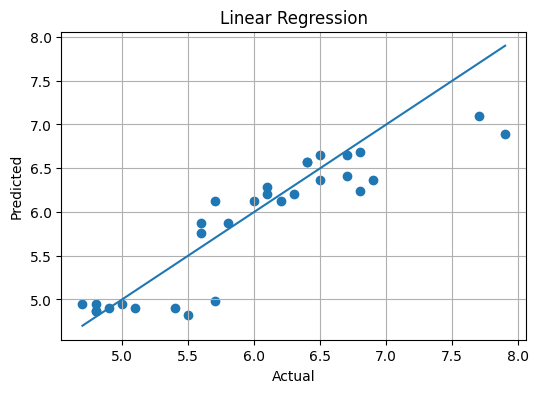

Multiple Regression
Intercept: 1.739890583076586
Coefficient: 0.759907753550026
 MSE:0.10
 RMSE:0.32
 R2:0.85


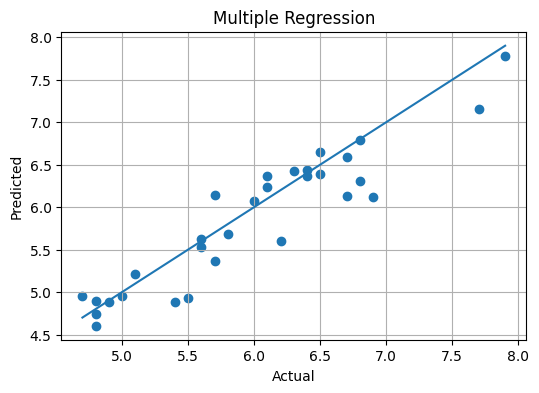

In [5]:
#Program 2 Linear Regression
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error,r2_score
data=pd.read_csv(r"D:\Sem3\iris.csv")
data.head()
x=data[['petal_length']]
y=data['sepal_length']
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)
lr=LinearRegression()
lr.fit(x_train,y_train)
result=lr.predict(x_test)
mse=mean_squared_error(y_test,result)
rmse=np.sqrt(mse)
r2=r2_score(y_test,result)
print("Intercept:",lr.intercept_)
print("Coefficient:",lr.coef_[0])
print(f" MSE:{mse:.2f}")
print(f" RMSE:{rmse:.2f}")
print(f" R2:{r2:.2f}")
plt.figure(figsize=(6,4))
plt.scatter(y_test,result)
plt.plot([min(y_test),max(y_test)],[min(y_test),max(y_test)])
plt.title("Linear Regression")
plt.xlabel("Actual")
plt.ylabel("Predicted")
plt.grid(True)
plt.show()
#multiple regression
print("Multiple Regression")
x=data[['petal_length','petal_width','sepal_width']]
y=data['sepal_length']
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)
lr=LinearRegression()
lr.fit(x_train,y_train)
result=lr.predict(x_test)
mse=mean_squared_error(y_test,result)
rmse=np.sqrt(mse)
r2=r2_score(y_test,result)
print("Intercept:",lr.intercept_)
print("Coefficient:",lr.coef_[0])
print(f" MSE:{mse:.2f}")
print(f" RMSE:{rmse:.2f}")
print(f" R2:{r2:.2f}")
plt.figure(figsize=(6,4))
plt.scatter(y_test,result)
plt.plot([min(y_test),max(y_test)],[min(y_test),max(y_test)])
plt.title("Multiple Regression")
plt.xlabel("Actual")
plt.ylabel("Predicted")
plt.grid(True)
plt.show()

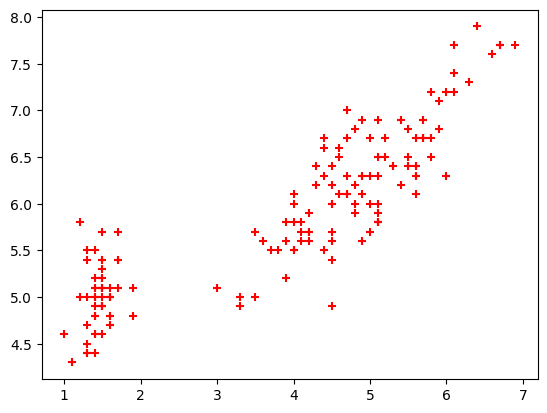

classification_report:               precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      1.00      1.00         9
   virginica       1.00      1.00      1.00        11

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30



In [6]:
#Logistic Regression
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report
from sklearn.linear_model import LogisticRegression
data=pd.read_csv(r"D:\Sem3\iris.csv")
plt.scatter(data.petal_length,data.sepal_length,marker='+',color='red')
plt.show()
x=data[['petal_length','sepal_length']]
y=data['species']
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)
lr=LogisticRegression()
lr.fit(x_train,y_train)
result=lr.predict(x_test)
lr.predict_proba(x_test)
lr.score(x_test,y_test)
print("classification_report:",classification_report(y_test,result))

Accuracy: 0.9649122807017544
Confusion Matrix:
 [[70  1]
 [ 3 40]]


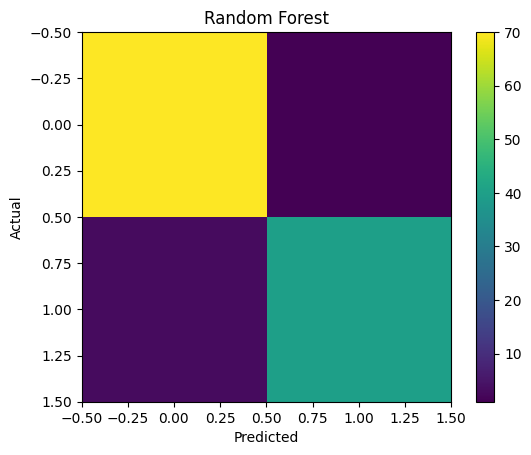

In [7]:
#BINARY classification
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix
df = pd.read_csv(r"D:\Sem3\data.csv")
df.diagnosis = df.diagnosis.map({"M":1,"B":0})
X = df.drop(columns=["diagnosis","id","Unnamed: 32"])
y = df.diagnosis
Xtrain,Xtest,ytrain,ytest = train_test_split(X,y,test_size=0.2,random_state=42)
m = RandomForestClassifier(n_estimators=100,random_state=42)
m.fit(Xtrain,ytrain)
p = m.predict(Xtest)
cm = confusion_matrix(ytest,p)
print("Accuracy:",accuracy_score(ytest,p))
print("Confusion Matrix:\n",cm)
plt.imshow(cm)
plt.xlabel("Predicted"); plt.ylabel("Actual")
plt.title("Random Forest"); plt.colorbar(); plt.show()

Accuracy: 1.0
Accuracy of Gaussian: 0.9666666666666667


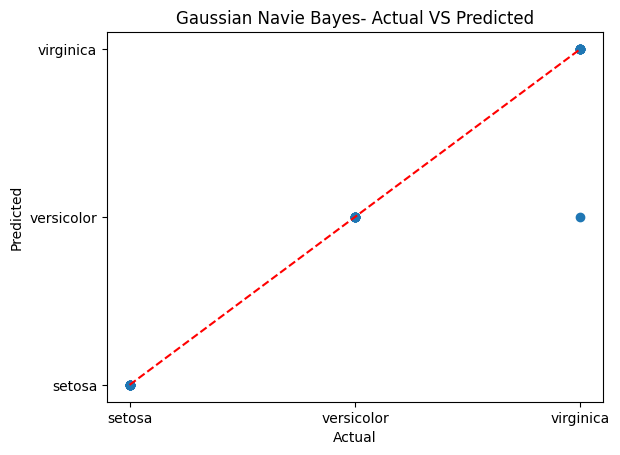

In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report,accuracy_score
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import LabelEncoder
data=pd.read_csv(r"D:\Sem3\iris.csv")
x=data.drop('species',axis=1)
y=data['species']
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=32)
n=KNeighborsClassifier()
n.fit(x_train,y_train)
r1=n.predict(x_test)
print("Accuracy:",accuracy_score(y_test,r1))
nb=GaussianNB()
nb.fit(x_train,y_train)
r2=nb.predict(x_test)
print("Accuracy of Gaussian:",accuracy_score(y_test,r2))
le=LabelEncoder()
le.fit(y)
plt.scatter(le.transform(y_test),le.transform(r2))
plt.plot([0,2],[0,2],'r--')
plt.xticks([0,1,2],le.classes_)
plt.yticks([0,1,2],le.classes_)
plt.title("Gaussian Navie Bayes- Actual VS Predicted")
plt.xlabel("Actual")
plt.ylabel("Predicted")
plt.show()

Classification Report:               precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      1.00      1.00         9
   virginica       1.00      1.00      1.00        11

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30

Accuracy: 1.0


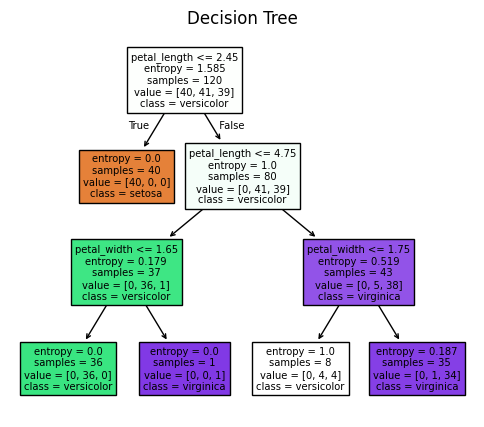

In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier,plot_tree
from sklearn.metrics import classification_report,accuracy_score
data=pd.read_csv(r"D:\Sem3\iris.csv")
x=data.drop('species',axis=1)
y=data['species']
dt=DecisionTreeClassifier(criterion='entropy',max_depth=3)
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)
dt.fit(x_train,y_train)
result=dt.predict(x_test)
print("Classification Report:",classification_report(y_test,result))
print("Accuracy:",accuracy_score(y_test,result))
plt.figure(figsize=(6,5))
plot_tree(dt,filled=True,feature_names=x.columns,class_names=y.unique())
plt.title("Decision Tree")
plt.show()

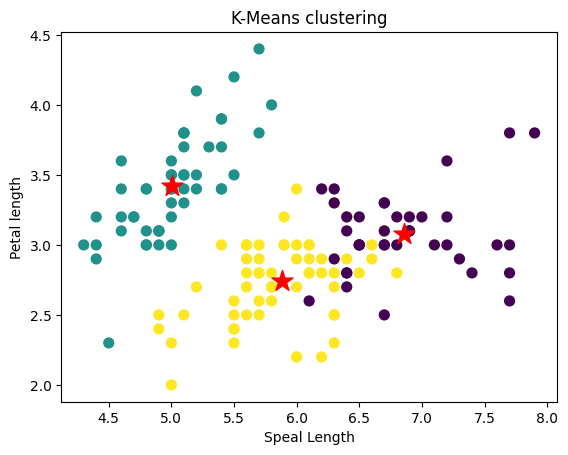

In [9]:
#Program 7 K-Means 
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
data=pd.read_csv(r"D:\Sem3\iris.csv")
x=data.drop('species',axis=1).values
kmeans=KMeans(n_clusters=3,random_state=42)
kmeans.fit(x)
cl=kmeans.labels_
ce=kmeans.cluster_centers_
plt.scatter(x[:,0],x[:,1],c=cl,cmap="viridis",s=50)
plt.scatter(ce[:,0],ce[:,1],c='red',s=250,marker='*')
plt.title("K-Means clustering")
plt.xlabel("Speal Length")
plt.ylabel("Petal length")
plt.show()

In [ ]:
#short code 8th code
import matplotlib.pyplot as plt
from tensorflow.keras import layers, models
from tensorflow.keras.datasets import mnist
from tensorflow.keras.utils import to_categorical
(x_train, y_train), (x_test, y_test) = mnist.load_data()
x_train = x_train.reshape(-1, 28, 28, 1) / 255.0
x_test = x_test.reshape(-1, 28, 28, 1) / 255.0
y_train = to_categorical(y_train)
y_test = to_categorical(y_test)
model = models.Sequential([
    layers.Conv2D(32, (3,3), activation='relu', input_shape=(28,28,1)),
    layers.MaxPooling2D((2,2)),
    layers.Conv2D(64, (3,3), activation='relu'),
    layers.MaxPooling2D((2,2)),
    layers.Flatten(),
    layers.Dense(64, activation='relu'),
    layers.Dense(10, activation='softmax')])
model.compile(optimizer='adam', loss='categorical_crossentropy',
              metrics=['accuracy'])
history = model.fit(x_train, y_train, epochs=5, batch_size=64,
                    validation_split=0.1)
loss, acc = model.evaluate(x_test, y_test)
print("Test Accuracy:", acc)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.show()
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()

In [ ]:
#short code  9
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.datasets import mnist
import matplotlib.pyplot as plt
(x_train, _), (x_test, _) = mnist.load_data()
x_train = x_train.reshape(-1, 784) / 255.0
x_test = x_test.reshape(-1, 784) / 255.0
inp = tf.keras.Input(shape=(784,))
encoded = layers.Dense(32, activation='relu')(inp)
decoded = layers.Dense(784, activation='sigmoid')(encoded)
model = models.Model(inp, decoded)
model.compile(optimizer='adam', loss='binary_crossentropy')
model.fit(x_train, x_train, epochs=5,batch_size=256,validation_data=(x_test, x_test))
output = model.predict(x_test[:5])
plt.figure(figsize=(10, 4))
for i in range(5):
    plt.subplot(2, 5, i+1)
    plt.imshow(x_test[i].reshape(28, 28), cmap='gray')
    plt.title("Original")
    plt.axis('off')
    plt.subplot(2, 5, i+6)
    plt.imshow(output[i].reshape(28, 28), cmap='gray')
    plt.title("Reconstructed")
    plt.axis('off')
plt.show()

In [ ]:
#Program 10
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow.keras import layers, models
from tensorflow.keras.datasets import imdb
from tensorflow.keras.preprocessing.sequence import pad_sequences
(x_train,y_train),(x_test,y_test)=imdb.load_data(num_words=10000)
x_train=pad_sequences(x_train,maxlen=100)
x_test=pad_sequences(x_test,maxlen=100)
model=models.Sequential([layers.Embedding(10000,128),layers.LSTM(128),layers.Dense(1,activation='sigmoid')])
model.compile(optimizer='adam',loss='binary_crossentropy',metrics=['accuracy'])
history=model.fit(x_train,y_train,epochs=5,batch_size=32,validation_split=0.1)
loss,acc=model.evaluate(x_test,y_test)
print("Test Accuracy:",acc)
plt.figure(figsize=(8, 6))
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.show()